# Unit 3 – Covariance and Pearson correlation
**Aim:** compute covariance and Pearson's r by hand and with libraries, then change the data points and observe how the statistics respond.

Pearson's r = cov(X, Y) / (σx · σy) and always lies in [-1, 1]. Covariance has the units of X×Y, so r is easier to compare across datasets.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
np.random.seed(42)
plt.rcParams['figure.figsize'] = (6, 4)
from scipy import stats

## 1. Baseline data: hours studied vs exam score

Manual covariance : 51.667
NumPy  covariance : 51.667
Manual Pearson r  : 0.9957
SciPy  Pearson r  : 0.9957


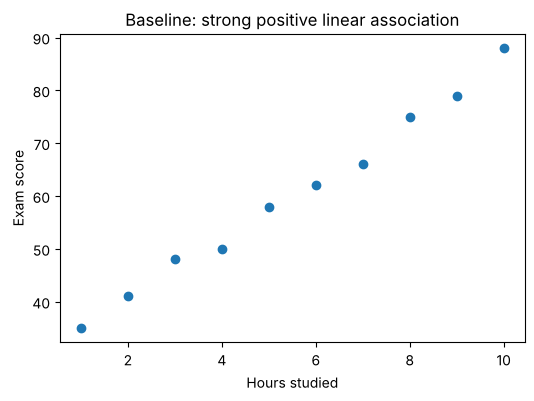

In [2]:
hours = np.array([1, 2, 3, 4, 5, 6, 7, 8, 9, 10], dtype=float)
score = np.array([35, 41, 48, 50, 58, 62, 66, 75, 79, 88], dtype=float)

def manual_cov(x, y):
    return np.sum((x - x.mean()) * (y - y.mean())) / (len(x) - 1)   # sample covariance

def manual_pearson(x, y):
    return manual_cov(x, y) / (x.std(ddof=1) * y.std(ddof=1))

print('Manual covariance :', round(manual_cov(hours, score), 3))
print('NumPy  covariance :', round(np.cov(hours, score)[0, 1], 3))
print('Manual Pearson r  :', round(manual_pearson(hours, score), 4))
print('SciPy  Pearson r  :', round(stats.pearsonr(hours, score)[0], 4))

plt.scatter(hours, score); plt.xlabel('Hours studied'); plt.ylabel('Exam score')
plt.title('Baseline: strong positive linear association'); plt.show()

## 2. Change the data points
Each scenario below edits the baseline and recomputes covariance and r.

In [3]:
def summary(name, x, y):
    return {'scenario': name, 'covariance': round(np.cov(x, y)[0, 1], 2),
            'pearson_r': round(stats.pearsonr(x, y)[0], 3),
            'p_value': float(f"{stats.pearsonr(x, y)[1]:.2e}")}

rows = [summary('Baseline', hours, score)]

# (a) one outlier: a student who studied 10 h but scored 10
s_out = score.copy(); s_out[-1] = 10
rows.append(summary('Outlier at x=10 (score 10)', hours, s_out))

# (b) increasing noise
for sd in (5, 15, 30):
    noisy = score + np.random.normal(0, sd, size=score.size)
    rows.append(summary(f'Noise sd={sd}', hours, noisy))

# (c) reverse the relationship
rows.append(summary('Reversed (score falls with hours)', hours, score[::-1]))

# (d) rescale units: covariance changes, r does not
rows.append(summary('Hours converted to minutes', hours * 60, score))

# (e) perfect non-linear relationship: y = x^2 on a symmetric range
xs = np.arange(-5, 6, dtype=float)
rows.append(summary('y = x^2 on [-5, 5]', xs, xs ** 2))

results = pd.DataFrame(rows); results

,scenario,covariance,pearson_r,p_value
0,Baseline,51.67,0.996,1.490000e-09
1,Outlier at x=10 (score 10),12.67,0.204,5.720000e-01
2,Noise sd=5,51.35,0.980,7.140000e-07
3,Noise sd=15,45.49,0.788,6.770000e-03
4,Noise sd=30,25.96,0.340,3.370000e-01
5,Reversed (score falls with hours),-51.67,-0.996,1.490000e-09
6,Hours converted to minutes,3100.00,0.996,1.490000e-09
7,"y = x^2 on [-5, 5]",0.00,-0.000,1.000000e+00


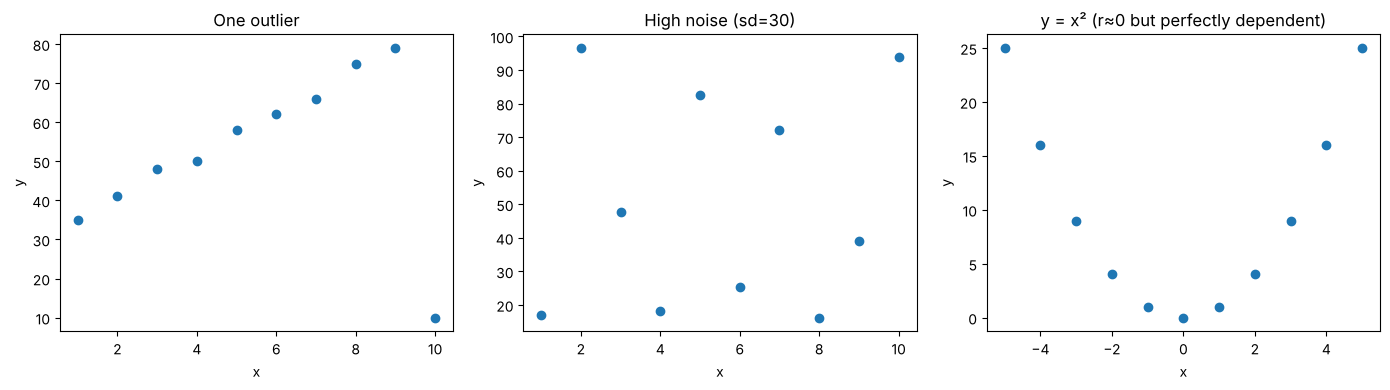

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
ax[0].scatter(hours, s_out); ax[0].set_title('One outlier')
ax[1].scatter(hours, score + np.random.normal(0, 30, 10)); ax[1].set_title('High noise (sd=30)')
ax[2].scatter(xs, xs ** 2); ax[2].set_title('y = x² (r≈0 but perfectly dependent)')
for a in ax: a.set_xlabel('x'); a.set_ylabel('y')
plt.tight_layout(); plt.show()

## 3. Correlation is not causation
Ice-cream sales and drowning incidents correlate strongly, but a third variable (temperature) drives both. The code simulates this confounder.

In [5]:
temp = np.random.uniform(10, 35, 200)
ice_cream = 20 * temp + np.random.normal(0, 60, 200)
drownings = 0.4 * temp + np.random.normal(0, 3, 200)
r_raw = stats.pearsonr(ice_cream, drownings)[0]

# remove the effect of temperature (partial correlation via residuals)
res_i = ice_cream - np.polyval(np.polyfit(temp, ice_cream, 1), temp)
res_d = drownings - np.polyval(np.polyfit(temp, drownings, 1), temp)
r_partial = stats.pearsonr(res_i, res_d)[0]
print(f'r(ice cream, drownings)                    = {r_raw:.3f}')
print(f'partial r after controlling for temperature = {r_partial:.3f}')

r(ice cream, drownings)                    = 0.644
partial r after controlling for temperature = -0.054


## Observations
* Baseline: covariance = 51.67 and r = 0.996, a near-perfect positive linear association.
* **One outlier** (10 hours, score 10) cut r from 0.996 to 0.204 and covariance from 51.67 to 12.67 – a single point can almost erase a strong relationship.
* **Noise** weakens r steadily: 0.980 (sd 5), 0.788 (sd 15), 0.340 (sd 30). At sd 30 the p-value (0.34) no longer supports a real relationship in only ten points.
* **Rescaling** hours to minutes multiplied covariance by 60 (3100) but left r unchanged – r is unit-free, covariance is not.
* y = x² has r ≈ 0 despite being perfectly dependent: Pearson only measures *linear* association.
* The confounder demo shows r = 0.644 between ice-cream sales and drownings, but the partial correlation after controlling for temperature is -0.054: the link was produced by a third variable, not causation.